# 多头注意力机制（Multi-Head Attention）

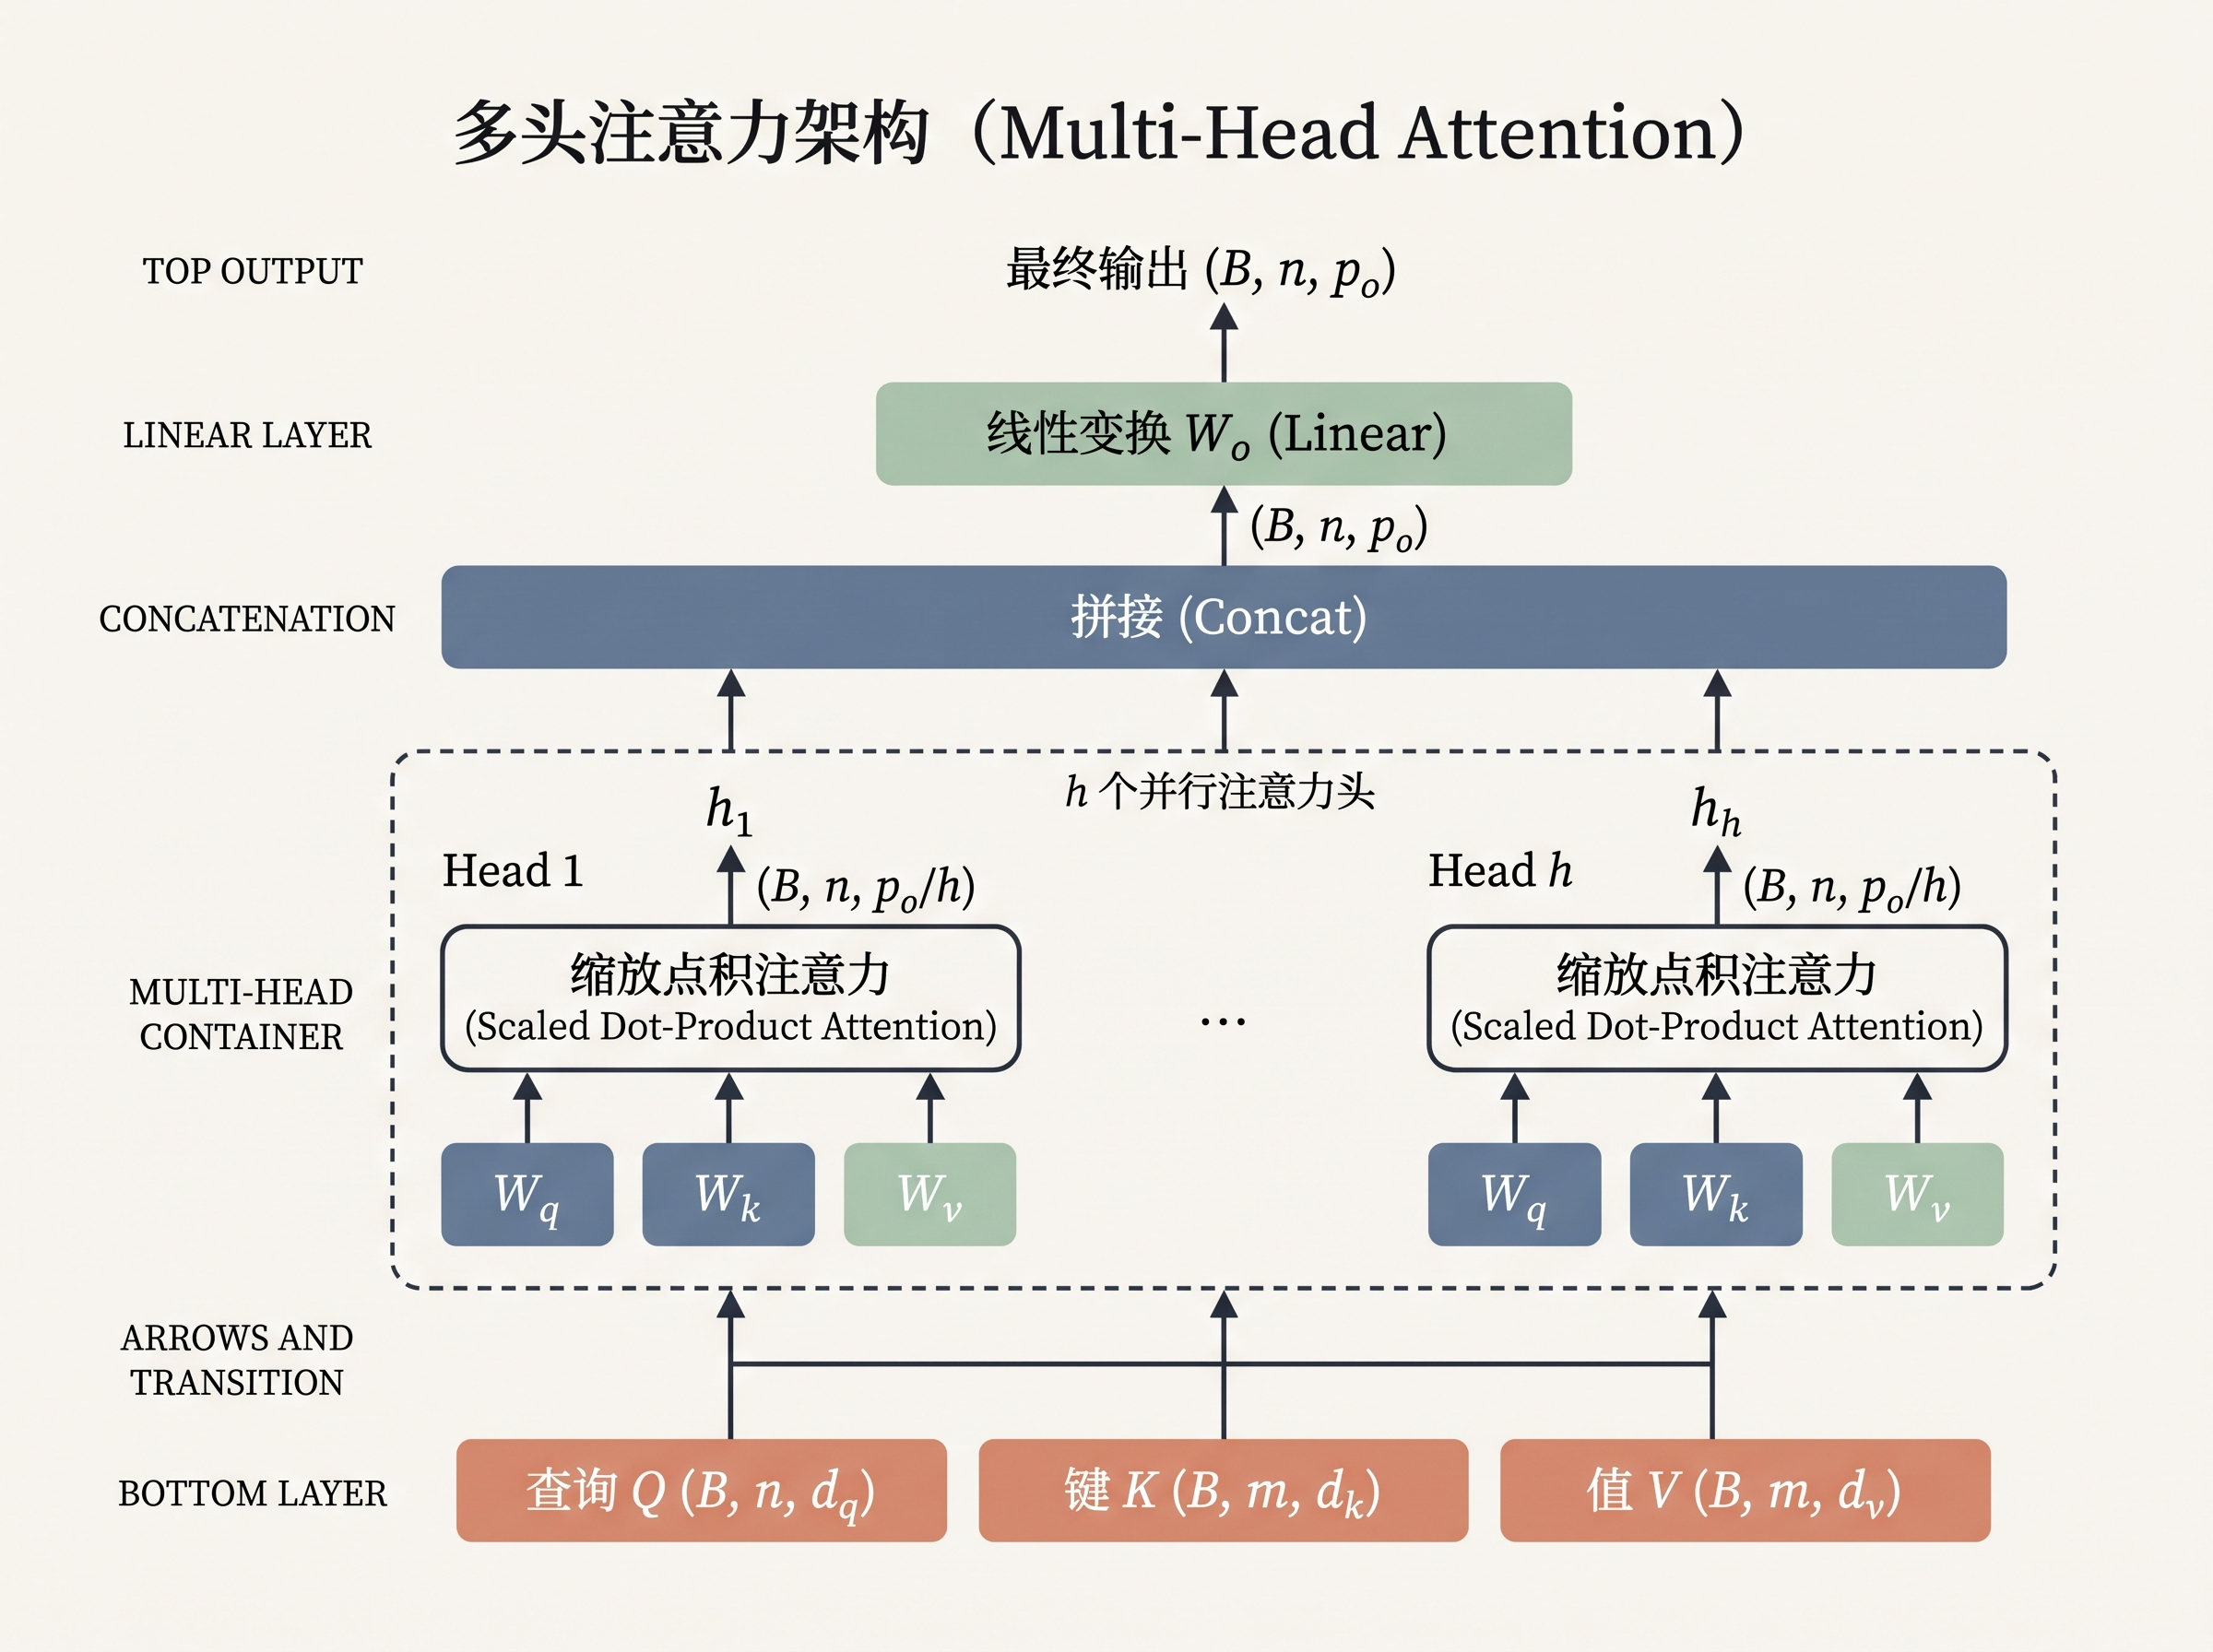
## 1. 背景

传统单头注意力通过 Query（Q）与 Key（K）计算注意力权重，再对 Value（V）加权求和，得到上下文表示。

但单个注意力头只能产生一套注意力权重，难以同时从多个角度充分捕捉信息之间的关系。

**多头注意力的核心思想：对同一批 Q、K、V 进行多组独立的可学习线性变换，使多个注意力头并行计算，最后将结果拼接并融合。**

例如，对于句子“我昨天在北京买了一本书”，不同注意力头可能分别关注动作主体、时间、地点和宾语等关系。这些分工由训练自动学习，并非人为指定。

## 2. 工作机制

### 2.1 线性投影：生成多个头的 Q、K、V

假设模型隐藏维度为 $d_{\text{model}}=512$，注意力头数为 $h=8$，则通常每个头的维度为：

$$
d_{\text{head}}=\frac{d_{\text{model}}}{h}=64
$$

第 $i$ 个注意力头通过独立的参数矩阵进行线性投影：

$$
Q_i=QW_i^Q,\quad K_i=KW_i^K,\quad V_i=VW_i^V
$$

其中 $W_i^Q,W_i^K,W_i^V$ 为第 $i$ 个头的可学习参数矩阵。

**不同头接收相同的原始输入，但使用不同的投影参数，因此能够学习不同的特征表示和注意力关系。**

注意：多头注意力不是简单地把原始特征均匀切分，而是先进行可学习线性投影，再组织成多个头。

### 2.2 并行计算注意力

每个头独立执行注意力计算，通常使用缩放点积注意力：

$$
\boxed{\text{head}_i=\operatorname{Softmax}\left(\frac{Q_iK_i^T}{\sqrt{d_k}}\right)V_i}
$$

其中：

- $Q_iK_i^T$：计算 Query 与 Key 的匹配分数。
- $\sqrt{d_k}$：缩放因子，避免点积过大导致 Softmax 梯度过小。
- $\operatorname{Softmax}$：将匹配分数转换为注意力权重。
- $V_i$：根据注意力权重加权求和，得到该头的输出。

各个头的计算过程相同，但由于投影参数不同，产生的注意力分布也可能不同。

### 2.3 拼接与输出投影

将所有注意力头的输出沿特征维度拼接：

$$
H=\operatorname{Concat}(\text{head}_1,\ldots,\text{head}_h)
$$

例如，8 个头各输出 64 维特征，拼接后得到 512 维表示。

随后通过输出线性层融合不同头的信息：

$$
O=HW^O
$$

其中 $W^O$ 是可学习的输出投影矩阵。

**Concat 负责汇集各头的信息，输出线性层负责学习不同头之间的特征组合。**

## 3. 完整数学表达式

$$
\boxed{\operatorname{MultiHead}(Q,K,V)=\operatorname{Concat}(\text{head}_1,\ldots,\text{head}_h)W^O}
$$

$$
\text{head}_i=\operatorname{Attention}(QW_i^Q,KW_i^K,VW_i^V)
$$

整体流程：

**原始 Q、K、V → 多组独立线性投影 → 各头并行计算注意力 → Concat 拼接 → 输出线性投影 → 最终输出。**

## 4. 与单头注意力的关系

| 对比 | 单头注意力 | 多头注意力 |
|---|---|---|
| 注意力权重 | 一套 | 多套 |
| 特征表示 | 单一注意力输出 | 多个投影子空间的注意力输出 |
| 计算方式 | 一次注意力计算 | 多个头并行计算 |
| 输出方式 | 加权求和 | 各头输出拼接后线性融合 |
| 主要优势 | 捕捉输入之间的相关性 | 从多个角度捕捉和组合相关信息 |

多头注意力本质上仍然遵循 Q、K、V 的注意力计算机制，并不是一种完全不同的算法。

此外，多头注意力与自注意力是两个不同概念：前者描述**使用多少个注意力头**，后者描述 **Q、K、V 的来源关系**。两者可以结合使用。

## 5. 核心结论

1. 多头注意力通过独立的可学习线性投影，让不同注意力头学习不同的特征表示。
2. 每个头内部仍然采用注意力权重对 Value 加权求和的机制。
3. 多个头的输出经过 Concat 拼接，再通过线性层进行特征融合。
4. 通常令 $d_{\text{head}}=d_{\text{model}}/h$，以控制整体计算规模。
5. 多头注意力增强了模型捕捉不同关系和表示子空间信息的能力，是 Transformer 的核心组件之一。

In [1]:
import math
import torch
from torch import nn
from d2l import torch as d2l

In [3]:
#@save
class MultiHeadAttention(nn.Module):
    """多头注意力"""
    def __init__(self, key_size, query_size, value_size, num_hiddens,
                 num_heads, dropout, bias=False, **kwargs):
        super(MultiHeadAttention, self).__init__(**kwargs)
        self.num_heads = num_heads
        self.attention = d2l.DotProductAttention(dropout)
        # 需要学习的线性层
        self.W_q = nn.Linear(query_size, num_hiddens, bias=bias)
        self.W_k = nn.Linear(key_size, num_hiddens, bias=bias)
        self.W_v = nn.Linear(value_size, num_hiddens, bias=bias)
        self.W_o = nn.Linear(num_hiddens, num_hiddens, bias=bias)

    def forward(self, queries, keys, values, valid_lens):
        # queries，keys，values的形状:
        # (batch_size，查询或者“键－值”对的个数，num_hiddens)
        # valid_lens　的形状:
        # (batch_size，)或(batch_size，查询的个数)
        # 经过变换后，输出的queries，keys，values　的形状:
        # (batch_size*num_heads，查询或者“键－值”对的个数，
        # num_hiddens/num_heads)
        queries = transpose_qkv(self.W_q(queries), self.num_heads)
        keys = transpose_qkv(self.W_k(keys), self.num_heads)
        values = transpose_qkv(self.W_v(values), self.num_heads)

        if valid_lens is not None:
            # 在轴0，将第一项（标量或者矢量）复制num_heads次，
            # 然后如此复制第二项，然后诸如此类。
            valid_lens = torch.repeat_interleave(
                valid_lens, repeats=self.num_heads, dim=0)

        # output的形状:(batch_size*num_heads，查询的个数，
        # num_hiddens/num_heads)
        output = self.attention(queries, keys, values, valid_lens)

        # output_concat的形状:(batch_size，查询的个数，num_hiddens)
        output_concat = transpose_output(output, self.num_heads)
        return self.W_o(output_concat)

In [ ]:
#@save
def transpose_qkv(X, num_heads):
    """为了多注意力头的并行计算而变换形状"""
    # 拆分后：(batch_size, 查询个数, 注意力头数, 每个头的特征维度)
    X = X.reshape(X.shape[0], X.shape[1], num_heads, -1)
    # 交换维度后：(batch_size, num_heads, 查询个数, head_dim)
    X = X.permute(0, 2, 1, 3)
    # 将 Batch 和 Head 合并
    return X.reshape(-1, X.shape[2], X.shape[3])


#@save
def transpose_output(X, num_heads):
    """逆转transpose_qkv函数的操作"""
    X = X.reshape(-1, num_heads, X.shape[1], X.shape[2])
    X = X.permute(0, 2, 1, 3)
    return X.reshape(X.shape[0], X.shape[1], -1)

In [5]:
num_hiddens, num_heads = 100, 5
attention = MultiHeadAttention(num_hiddens, num_hiddens, num_hiddens,
                               num_hiddens, num_heads, 0.5)
attention.eval()

MultiHeadAttention(
  (attention): DotProductAttention(
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (W_q): Linear(in_features=100, out_features=100, bias=False)
  (W_k): Linear(in_features=100, out_features=100, bias=False)
  (W_v): Linear(in_features=100, out_features=100, bias=False)
  (W_o): Linear(in_features=100, out_features=100, bias=False)
)

In [6]:
batch_size, num_queries = 2, 4
num_kvpairs, valid_lens =  6, torch.tensor([3, 2])
X = torch.ones((batch_size, num_queries, num_hiddens))
Y = torch.ones((batch_size, num_kvpairs, num_hiddens))
attention(X, Y, Y, valid_lens).shape

torch.Size([2, 4, 100])

## 总结
多头注意力首先通过可学习的线性层 $W_q$、$W_k$、$W_v$ 对原始 Q、K、V 进行投影。由于不同注意力头对应的参数矩阵不同，因此即使输入相同，各个头也可能学习到不同的特征表示，进而产生不同的注意力权重和输出。

在计算过程中，通过 `reshape` 和 `permute` 将不同 Batch 的不同注意力头组织到同一个批量维度中，利用 `bmm` 并行计算各个头的注意力，且不同样本、不同头之间不会相互混合信息。

随后，`transpose_output` 将并行计算的结果还原到对应的 Batch 和注意力头，并通过 `output_concat` 将各个头的特征拼接起来，最后经过线性层 $W_o$ 融合，得到最终的特征表示

**多头注意力的核心在于：通过不同的可学习投影，使多个注意力头能够从不同的表示子空间提取信息，并利用批量矩阵乘法高效并行计算。** 不同头可能关注不同的语法、语义或位置关系，但这只是直观解释，实际关注的特征由模型自主学习，并不具有预先规定的明确分工，即所谓的黑盒